In [26]:
# Notebook bootstrap: auto-enable local src/ package
import sys
from pathlib import Path

# Detect project root (parent of notebooks/)
project_root = Path.cwd().resolve().parent

# Deduplicate sys.path
sys.path = [p for p in sys.path if not p.endswith("/src")]

# Add project root
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Using project root:", project_root)


Using project root: /home/mbz/Documents/PhD/SCD41_DATA


In [ ]:

import logging
from config import PipelineConfig
from src.pipeline import SensorPipeline

# Setup logging
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(name)s - %(levelname)s - %(message)s',
    handlers=[
        logging.FileHandler('../notebooks/logs/processing.log'),
        logging.StreamHandler()
    ]
)

In [32]:
# Load configuration
config = PipelineConfig.from_yaml(Path('../config/sensors.yaml'))

print(f"Loaded {len(config.sensors)} sensors:")
for s in config.sensors:
    print(f"  - {s.name} ({s.sensor_type}, altitude: {s.altitude_m}m)")

Loaded 5 sensors:
  - CO2_SCT1_2M (scd41, altitude: 2m)
  - CO2_30M_A (scd41, altitude: 30m)
  - CO2_30M_B (scd41, altitude: 30m)
  - CO2_30M_C (scd41, altitude: 30m)
  - LGR_30M (lgr_csv, altitude: 30m)


In [33]:
# Process specific month - testing Sep 2024
pipeline = SensorPipeline(config, force=False)
pipeline.run_all(year=2024, month=9)

2025-12-08 20:40:45,297 - src.pipeline - INFO - Starting pipeline for all sensors
2025-12-08 20:40:45,298 - src.pipeline - INFO - ============================================================
2025-12-08 20:40:45,299 - src.pipeline - INFO - Processing sensor: CO2_SCT1_2M
2025-12-08 20:40:45,300 - src.pipeline - INFO - ============================================================
2025-12-08 20:40:45,445 - src.pipeline - INFO - Found 19 days ((2024, 9, 12) to (2024, 9, 30))
2025-12-08 20:40:45,445 - src.processor - INFO - Processing 2024-09-12 (13 files)
2025-12-08 20:40:47,793 - src.processor - INFO - Removed 31389 duplicate timestamps
2025-12-08 20:40:47,796 - src.uptime - WARNING - Unexpected sample interval: 2.0s (expected ~60s)
2025-12-08 20:40:47,822 - src.processor - INFO - ✓ 2024-09-12: 16068 raw → 67 10-min samples (uptime: 100.0%)
2025-12-08 20:40:47,828 - src.processor - INFO - Processing 2024-09-13 (24 files)
2025-12-08 20:40:52,955 - src.processor - INFO - Removed 68209 duplica

In [34]:
# Reprocess specific period (testing force mode)
pipeline = SensorPipeline(config, force=True)
pipeline.run_all(year=2024, month=10)

2025-12-08 20:44:52,179 - src.pipeline - INFO - Starting pipeline for all sensors
2025-12-08 20:44:52,181 - src.pipeline - INFO - ============================================================
2025-12-08 20:44:52,181 - src.pipeline - INFO - Processing sensor: CO2_SCT1_2M
2025-12-08 20:44:52,182 - src.pipeline - INFO - ============================================================
2025-12-08 20:44:52,246 - src.pipeline - INFO - Found 31 days ((2024, 10, 1) to (2024, 10, 31))
2025-12-08 20:44:52,246 - src.processor - INFO - Processing 2024-10-01 (24 files)
2025-12-08 20:44:57,427 - src.processor - INFO - Removed 71891 duplicate timestamps
2025-12-08 20:44:57,429 - src.uptime - WARNING - Unexpected sample interval: 4.0s (expected ~60s)
2025-12-08 20:44:57,465 - src.processor - INFO - ✓ 2024-10-01: 31513 raw → 145 10-min samples (uptime: 100.0%)
2025-12-08 20:44:57,469 - src.processor - INFO - Processing 2024-10-02 (24 files)
2025-12-08 20:45:02,822 - src.processor - INFO - Removed 75893 dupli

KeyboardInterrupt: 

Generating plots...
  - CO2_SCT1_2M: Uptime timeseries


2025-12-08 20:50:31,712 - src.visualization - INFO - Saved: CO2_SCT1_2M_uptime_timeseries.png


  - CO2_SCT1_2M: Uptime heatmap


2025-12-08 20:50:32,085 - src.visualization - INFO - Saved: CO2_SCT1_2M_uptime_heatmap.png


  - CO2_SCT1_2M: QC summary


2025-12-08 20:50:32,444 - src.visualization - INFO - Saved: CO2_SCT1_2M_qc_summary.png


... (6 outputs left out)

  - Multi-sensor uptime summary


2025-12-08 20:50:33,693 - src.visualization - INFO - Saved: uptime_summary_all_sensors.png
/home/mbz/Documents/PhD/SCD41_DATA/src/visualization.py:265: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
/home/mbz/Documents/PhD/SCD41_DATA/src/visualization.py:270: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(self.output_dir / filename, dpi=300, bbox_inches='tight')


  - CO2 timeseries comparison


2025-12-08 20:50:34,091 - src.visualization - INFO - Saved: co2_timeseries.png
/home/mbz/Documents/PhD/SCD41_DATA/venv/lib/python3.12/site-packages/IPython/core/events.py:96: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  func(*args, **kwargs)


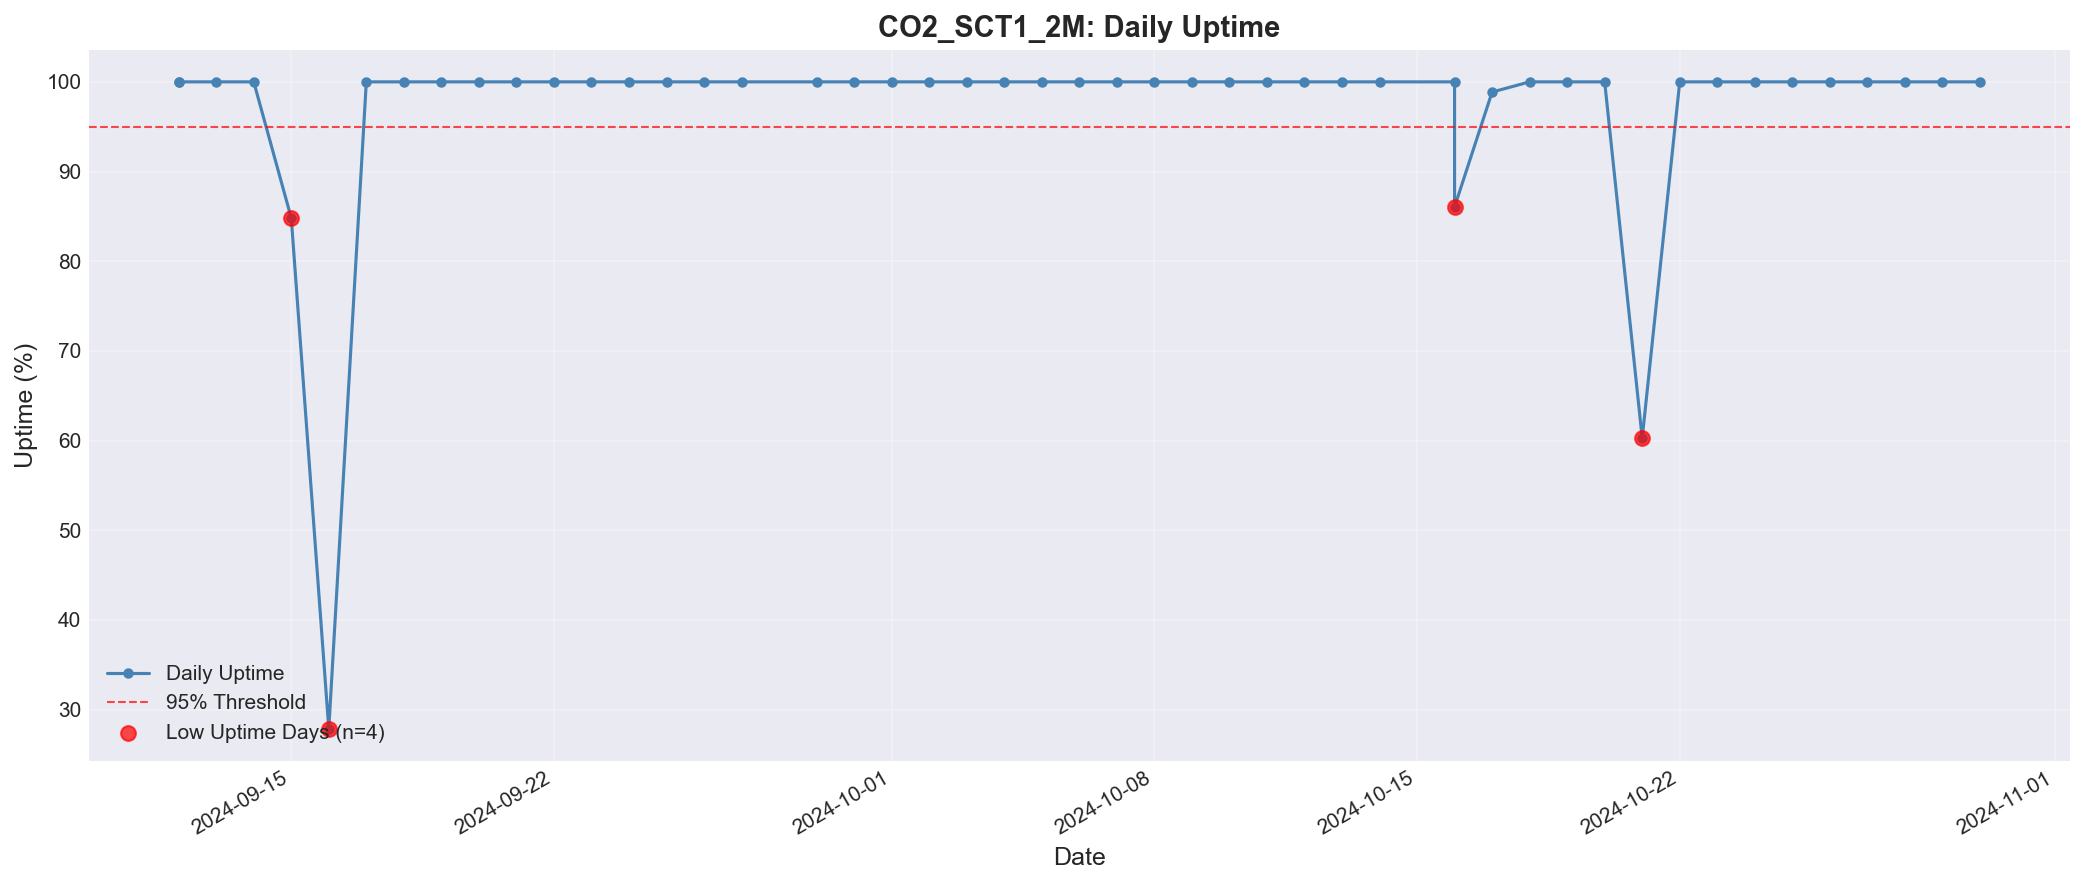

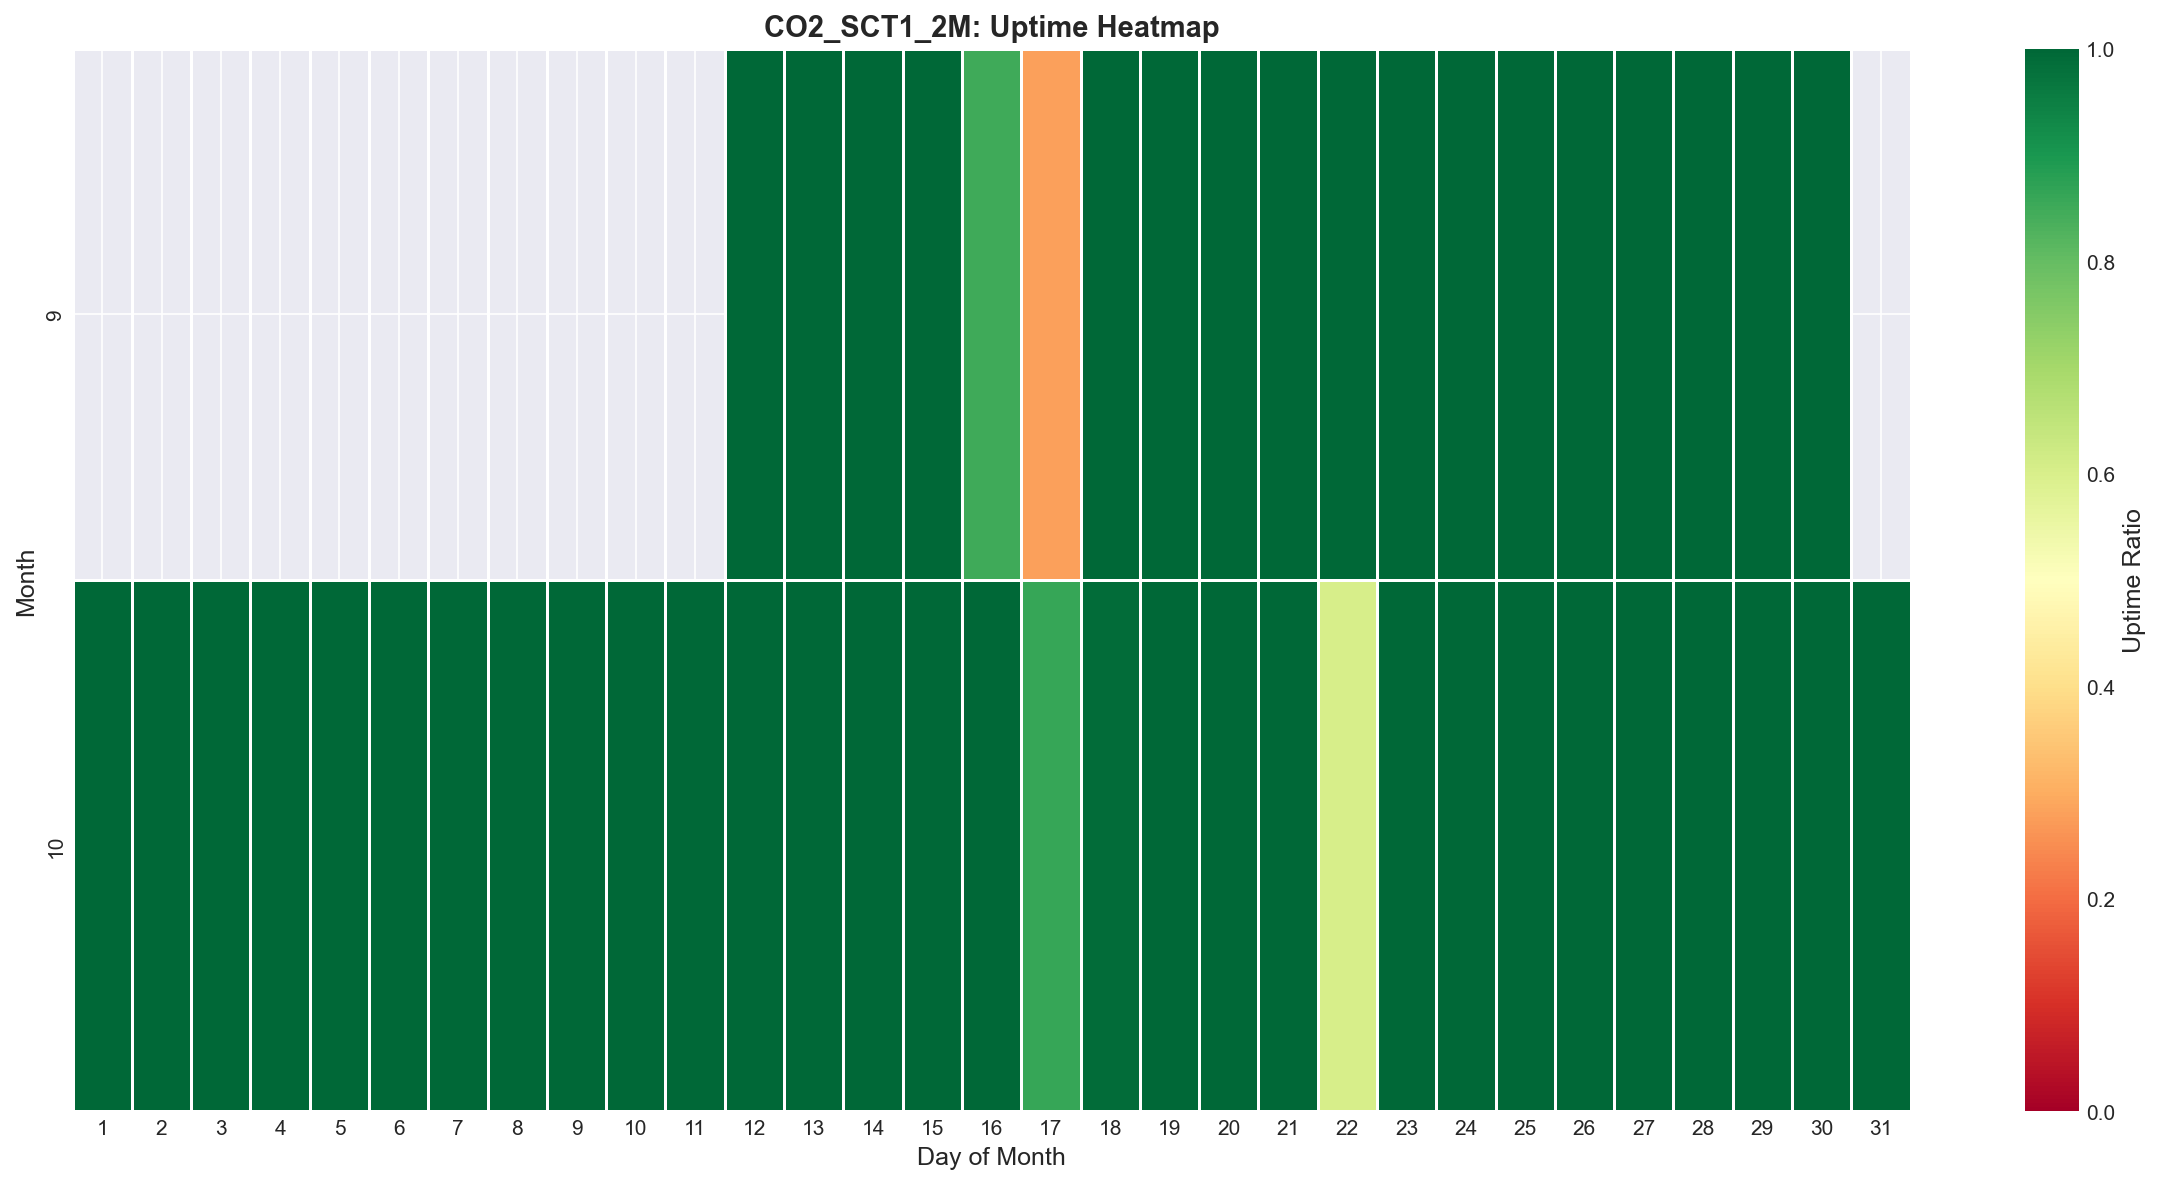

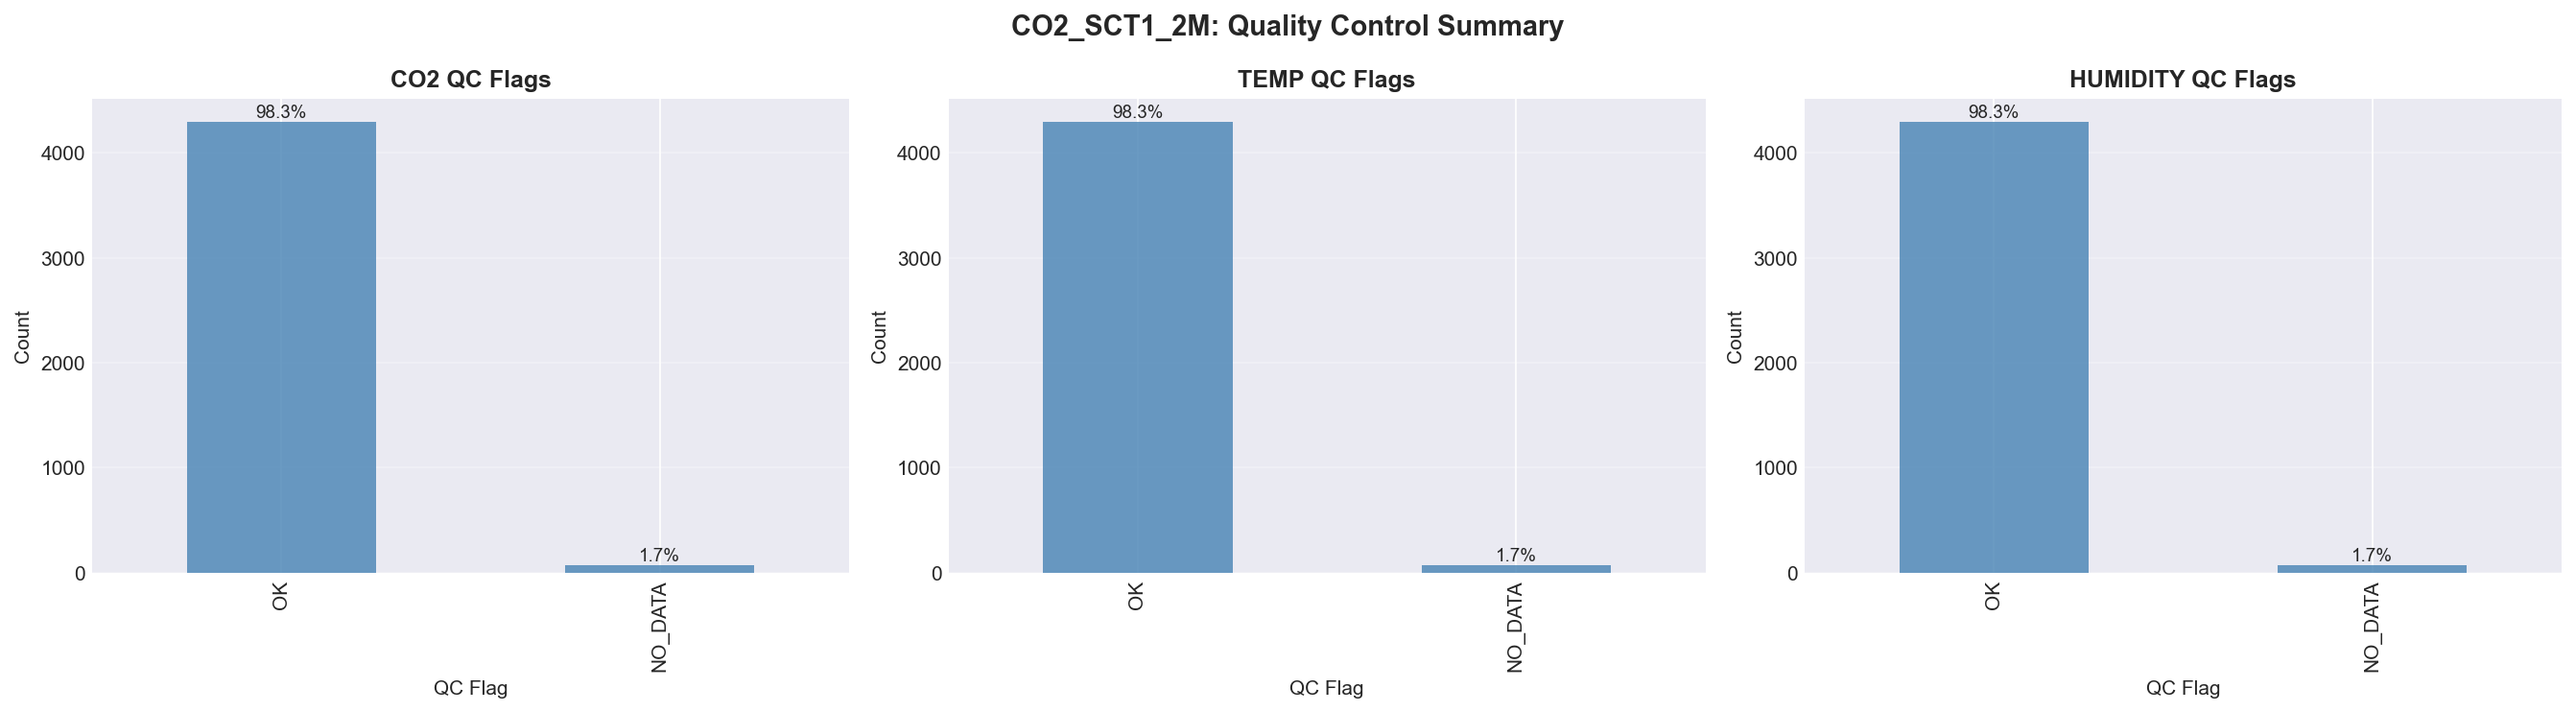

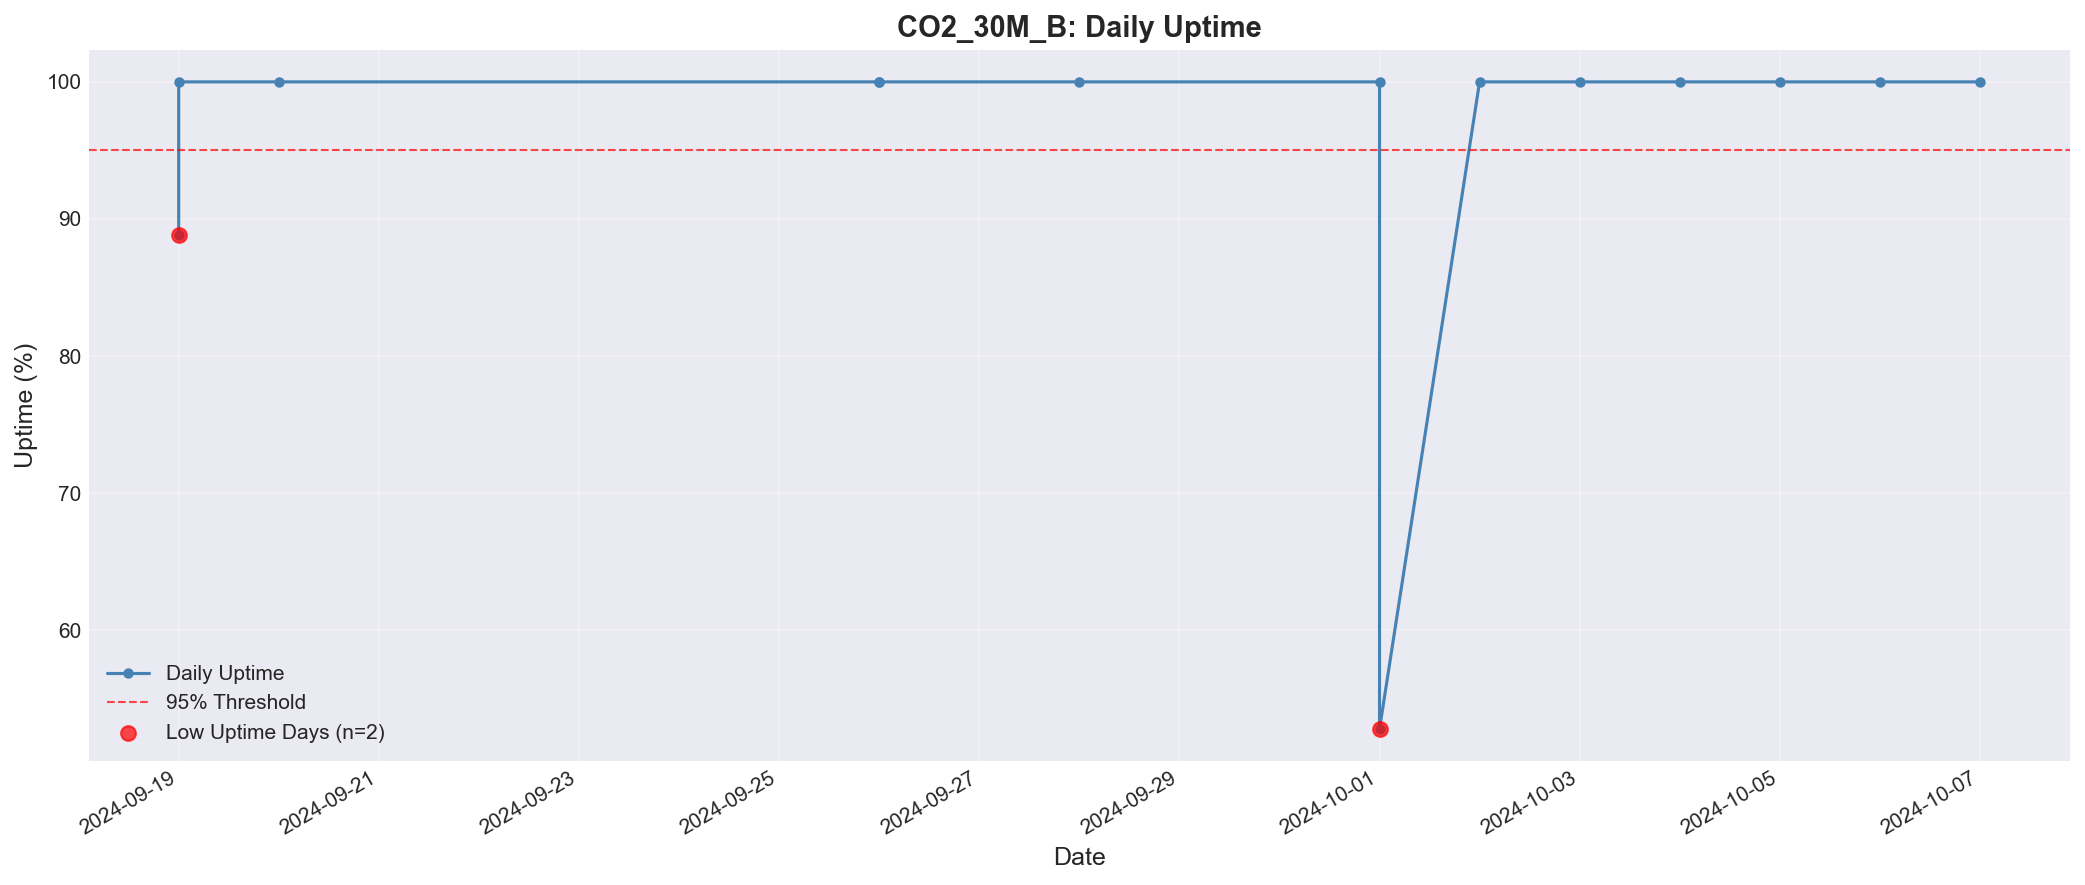

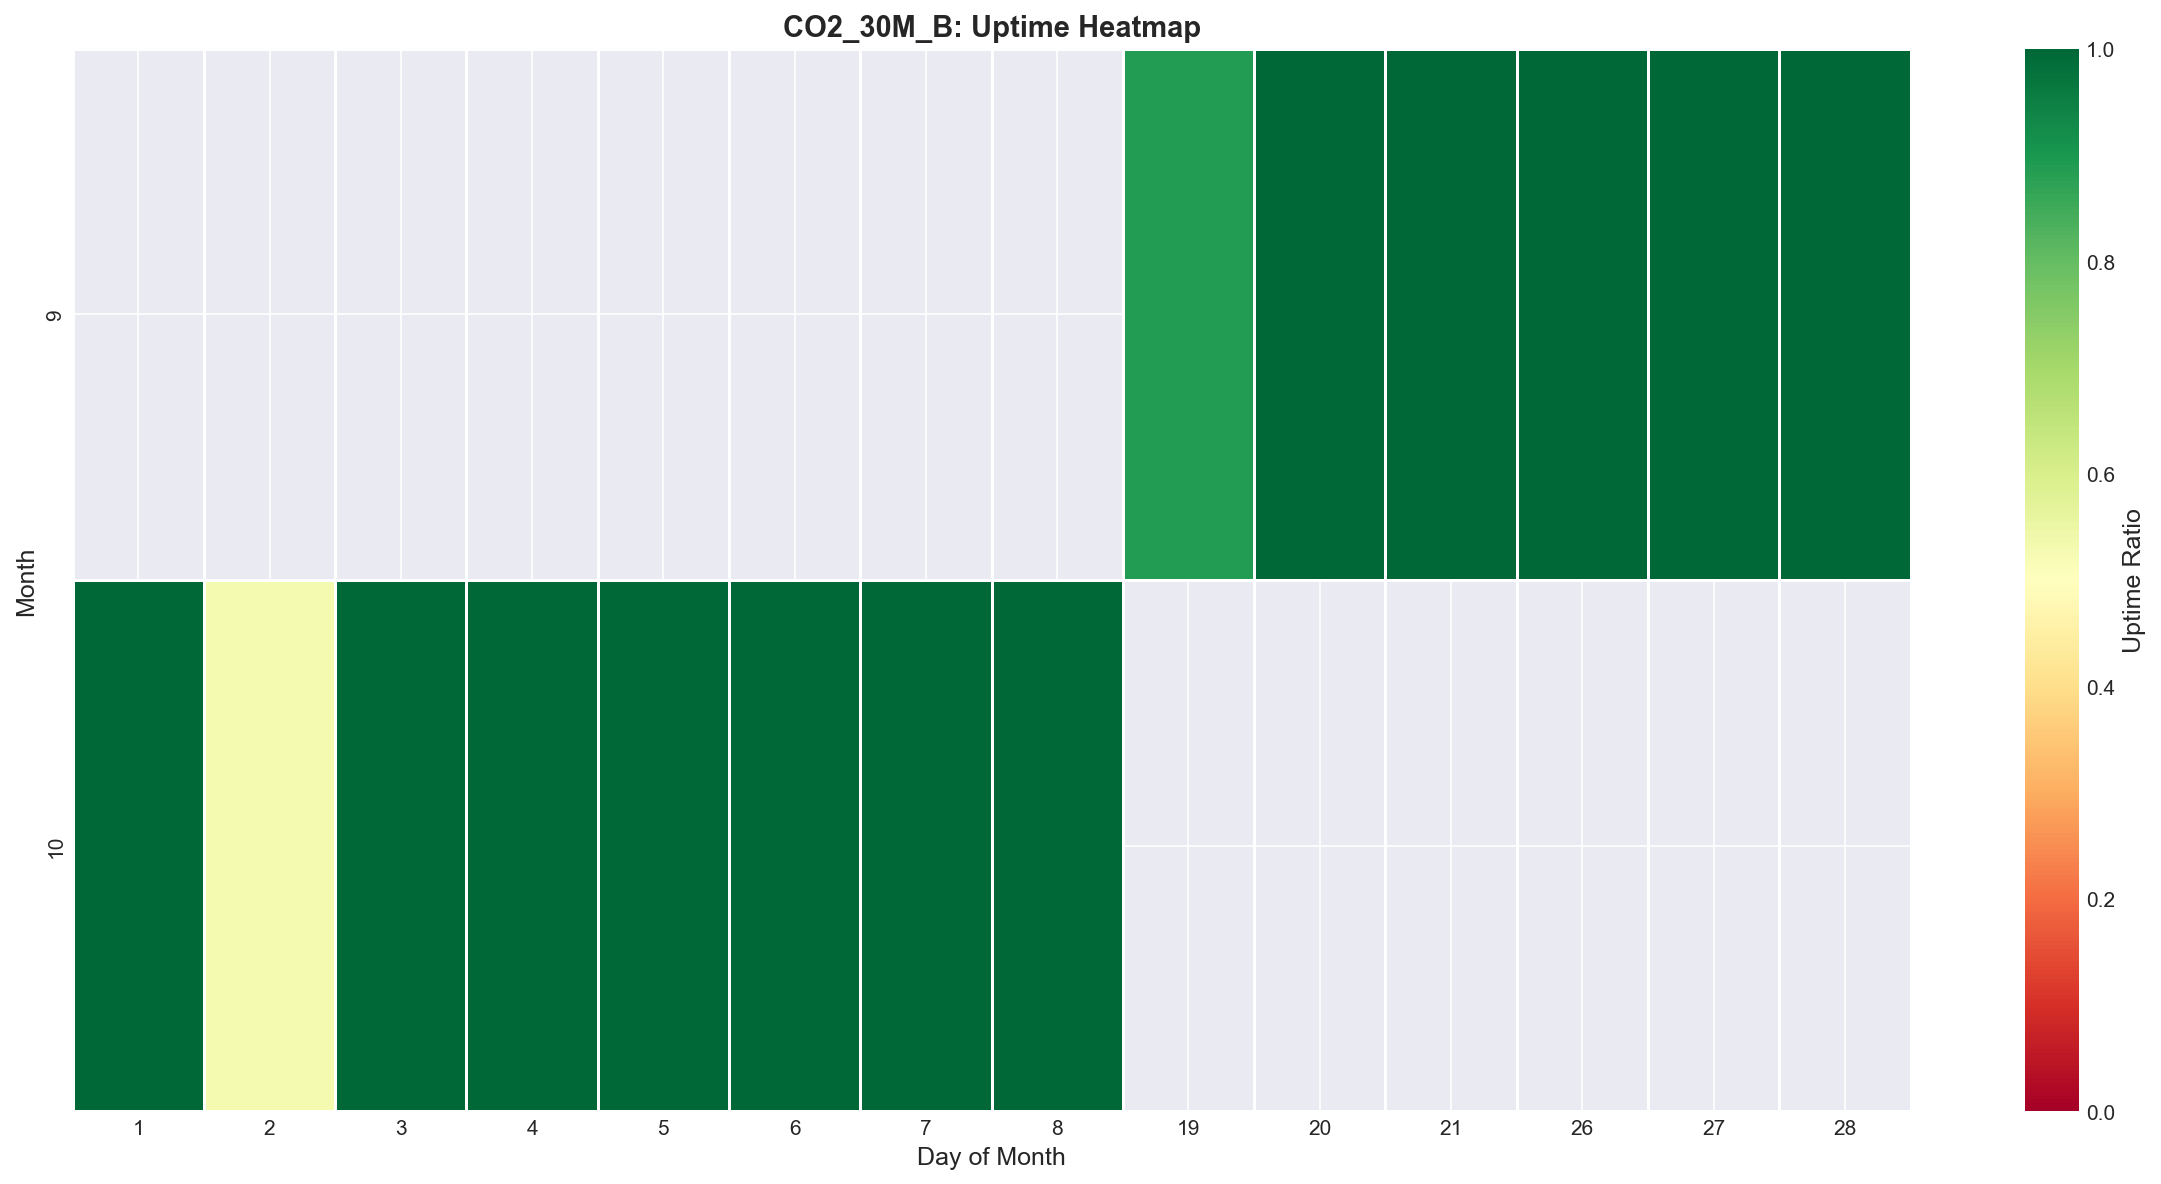

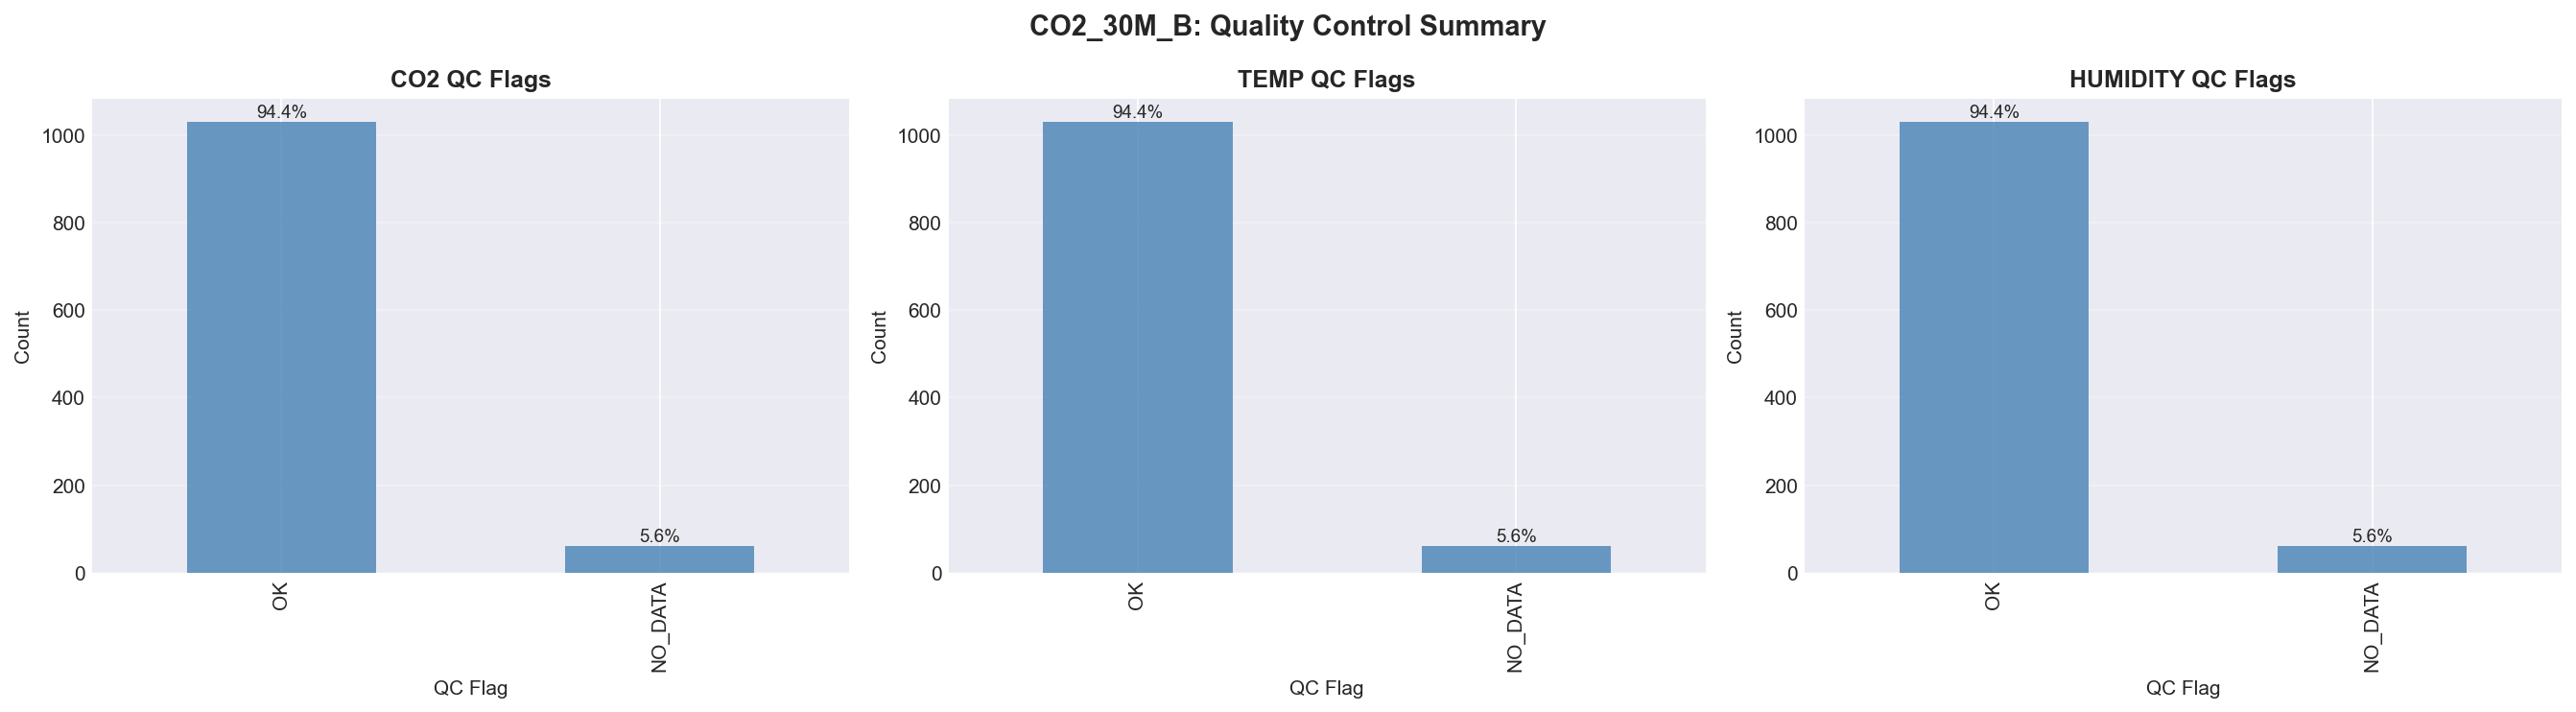

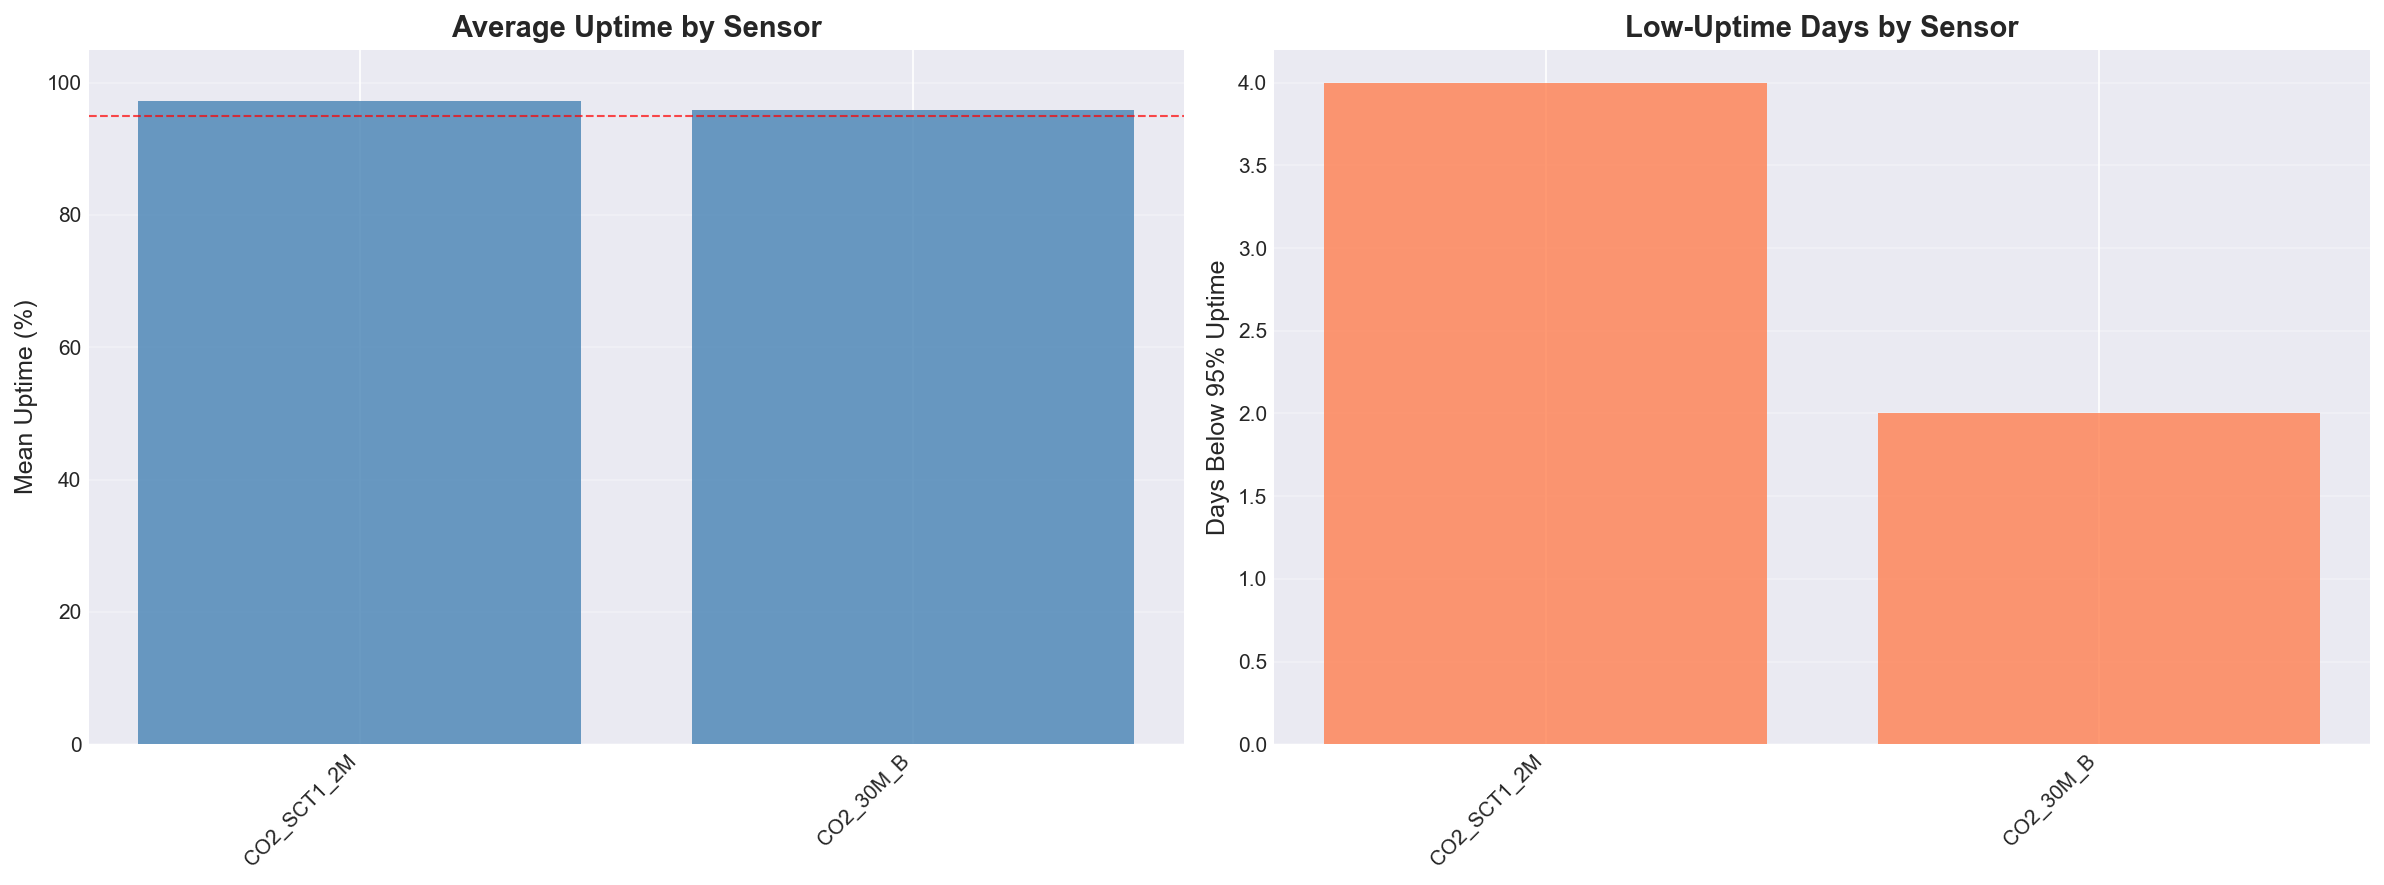

/home/mbz/Documents/PhD/SCD41_DATA/venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


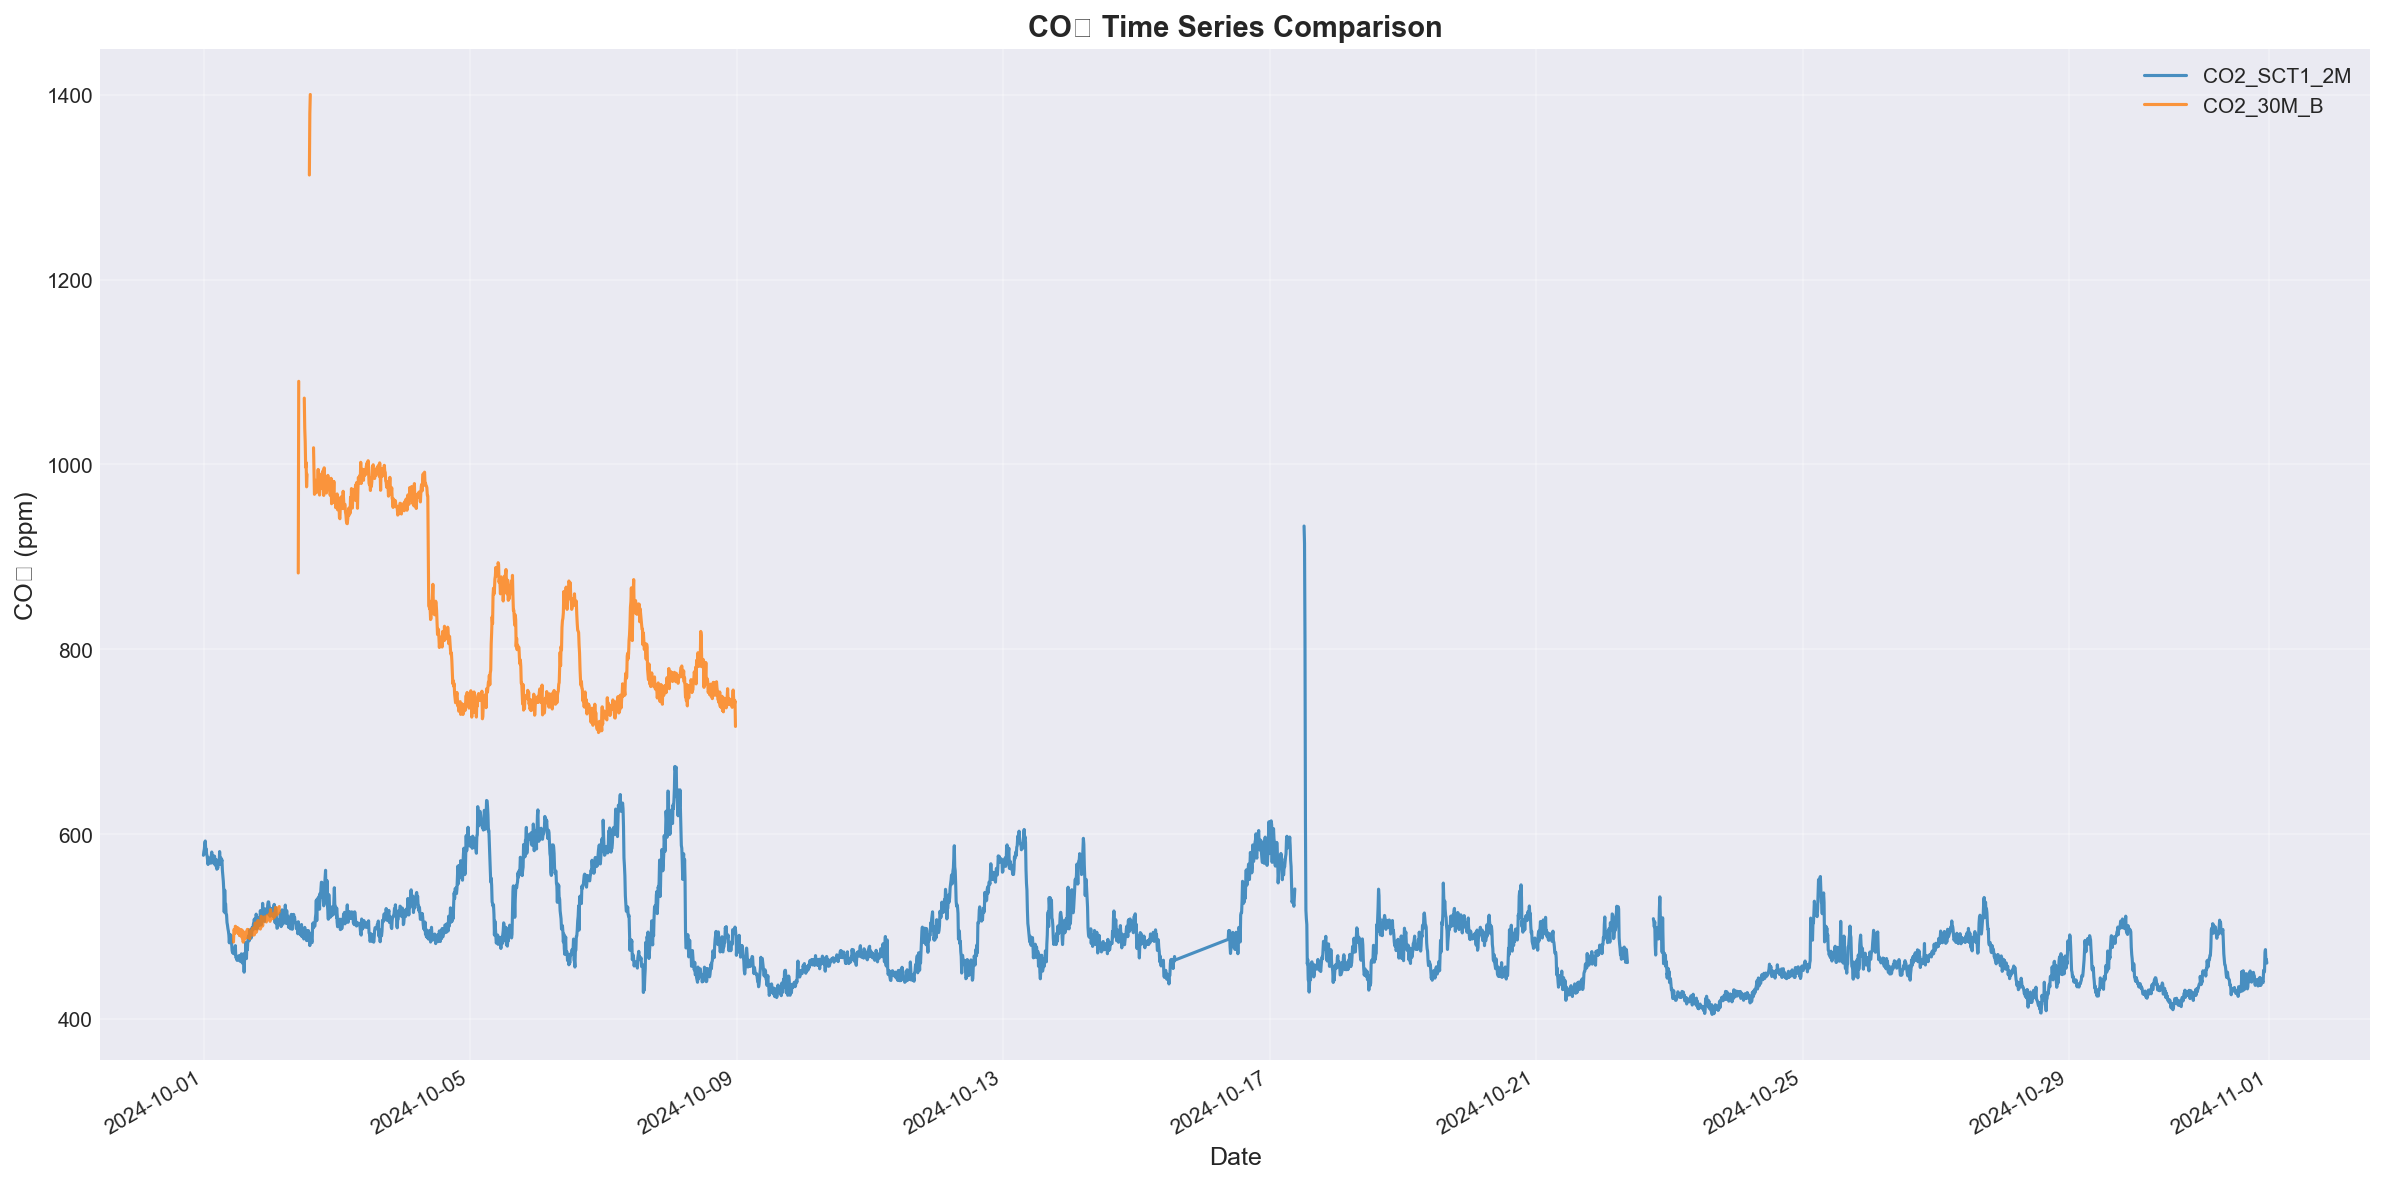

In [35]:
from src.visualization import generate_all_plots

generate_all_plots(
    individual_dir=config.output_dir,
    sensor_names=[s.name for s in config.sensors],
    output_dir=Path('../output/plots')
)

In [ ]:
# Process all sensors (all time)
# pipeline = SensorPipeline(config, force=False)
# pipeline.run_all()